# 04 · Model benchmark

**Protocol (identical for every model):** 211 weekly series; 4 rolling-origin (expanding-window) CV folds, each with a 13-week test window, plus a final untouched 13-week holdout (2016-02-20 to 2016-05-14). Each model is refit at every origin on data up to that origin only. Forecasts are clipped at 0 for all models.

Training is expensive (about 45 min on 4 cores), so it runs via `make train`; `make eval` scores it. This notebook re-runs the **scoring** step from the cached forecasts and explains the results.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
def show(fig): display(Image(filename=f"reports/figures/{fig}"))
def J(path): return json.load(open(path))

## Models and why each is in the race
| Model | Idea | Assumptions | Should work when | Should fail when |
|---|---|---|---|---|
| Naive | next = last value | random walk | level changes unpredictably | strong seasonality |
| SeasonalNaive | next = same week last year | stable annual pattern, no growth | strong, stable seasonality | trend / growth, moving holidays |
| MovingAverage (4 wk) | mean of last 4 weeks | locally constant level | noisy, no structure | trend, seasonality |
| SES | exponentially weighted level | level only | noisy, slowly drifting level | trend, seasonality |
| ETS | level + (damped) trend + season states, chosen by AICc | errors ~ Gaussian, stable components | smooth, seasonal series | zeros (multiplicative not allowed), 52 seasonal states to initialise |
| SARIMA | ARIMA on differenced data incl. lag-52 terms (AutoARIMA) | linear, Gaussian, constant parameters after differencing | smooth aggregates with stable seasonal and trend dynamics | intermittent counts, short history, breaks, drivers it cannot see |
| DHR-ARIMA | Fourier (period 52.18) + holiday + SNAP regressors + ARIMA errors | smooth seasonality, linear effects | non-integer period, moving holidays, known drivers | sharp, irregular seasonal shapes |
| Prophet | piecewise-linear trend + Fourier + holidays + SNAP regressor | additive components, changepoints | multiple seasonalities, holidays | short-term autocorrelation, intermittent data |
| LightGBM (global) | one gradient-boosted tree model for all series, scaled target, lags + calendar + price | stationarity of relationships across series and time | many related series, nonlinear and exogenous effects | extrapolating trends beyond the training range |
| Ensemble | mean of the best statistical model (by CV) and LightGBM | errors not perfectly correlated | the two models fail differently | one model is much worse |

In [2]:
import contextlib, io
from src.evaluation import evaluate
with contextlib.redirect_stdout(io.StringIO()):
    evaluate.main()
EV = J("reports/evaluation_summary.json")
print("ensemble components (chosen on CV only):", EV["ensemble_components"])
print("statistical models ranked by CV mean MASE:", EV["stat_rank_cv_mean_MASE"])

ensemble components (chosen on CV only): ['SARIMA', 'LightGBM']
statistical models ranked by CV mean MASE: {'SARIMA': 0.7011, 'DHR-ARIMA': 0.7077, 'ETS': 0.75, 'Prophet': 0.7737}


## 1. Overall leaderboards (CV folds = model selection; holdout = final check)

In [3]:
cols = ["model", "median_WAPE", "pooled_WAPE", "mean_MASE", "median_MASE", "median_Bias"]
display(pd.read_csv("reports/tables/leaderboard_cv_overall.csv")[cols].round(3))
display(pd.read_csv("reports/tables/leaderboard_holdout_overall.csv")[cols].round(3))

,model,median_WAPE,pooled_WAPE,mean_MASE,median_MASE,median_Bias
0,Ensemble,0.416,0.054,0.681,0.617,-0.005
1,SARIMA,0.430,0.054,0.701,0.637,-0.008
2,DHR-ARIMA,0.442,0.052,0.708,0.656,-0.004
3,LightGBM,0.405,0.064,0.712,0.627,0.003
4,ETS,0.430,0.064,0.750,0.643,-0.002
5,SES,0.434,0.073,0.772,0.678,-0.011
6,Prophet,0.462,0.065,0.774,0.689,-0.040
7,MovingAverage,0.431,0.073,0.789,0.698,-0.002
8,Naive,0.471,0.079,0.860,0.737,-0.035
9,SeasonalNaive,0.565,0.102,1.020,0.922,-0.111


,model,median_WAPE,pooled_WAPE,mean_MASE,median_MASE,median_Bias
0,Ensemble,0.301,0.042,0.668,0.585,0.004
1,LightGBM,0.323,0.045,0.678,0.607,0.017
2,SARIMA,0.278,0.043,0.699,0.579,-0.006
3,DHR-ARIMA,0.424,0.042,0.728,0.644,-0.011
4,ETS,0.298,0.053,0.739,0.629,-0.025
5,SES,0.293,0.058,0.748,0.674,-0.013
6,MovingAverage,0.299,0.057,0.752,0.671,-0.026
7,Prophet,0.382,0.082,0.789,0.691,-0.033
8,Naive,0.347,0.056,0.826,0.671,-0.018
9,SeasonalNaive,0.484,0.145,1.051,0.879,-0.059


**How to read it:** *median WAPE* is the typical series' error as a share of its volume (dominated by the 120 SKUs, where errors of 40-70% are normal for weekly item demand); *pooled WAPE* weights by volume; *mean MASE* is the cross-series ranking metric (< 1 = better than the in-sample seasonal naive).

**Observed (CV):** Ensemble 0.681 < SARIMA 0.701 < DHR-ARIMA 0.708 < LightGBM 0.712 < ETS 0.750 < SES 0.772 < Prophet 0.774 < MovingAverage 0.789 < Naive 0.860 < **SeasonalNaive 1.020**.
**Holdout** keeps the same top group (Ensemble 0.668, LightGBM 0.678, SARIMA 0.699), so the CV ranking was not a fluke of the folds.

## 2. By series group: aggregates vs SKUs

In [4]:
g = pd.read_csv("reports/tables/leaderboard_cv_by_group.csv")
display(g.pivot(index="model", columns="group", values=["mean_MASE", "median_WAPE", "pooled_WAPE", "median_Bias"]).round(3).sort_values(("mean_MASE", "Aggregates (91)")))
gh = pd.read_csv("reports/tables/leaderboard_holdout_by_group.csv")
display(gh.pivot(index="model", columns="group", values=["mean_MASE", "pooled_WAPE"]).round(3))

mean_MASE               median_WAPE               pooled_WAPE               median_Bias          
group         Aggregates (91) SKU (120) Aggregates (91) SKU (120) Aggregates (91) SKU (120) Aggregates (91) SKU (120)
model                                                                                                                
Ensemble                0.621     0.727           0.074     0.703           0.054     0.575          -0.005    -0.009
SARIMA                  0.636     0.751           0.079     0.738           0.053     0.608          -0.006    -0.033
DHR-ARIMA               0.646     0.754           0.078     0.715           0.051     0.613          -0.003    -0.015
LightGBM                0.686     0.733           0.080     0.703           0.063     0.571          -0.006     0.022
ETS                     0.725     0.769           0.094     0.767           0.063     0.653          -0.002    -0.020
Prophet                 0.727     0.809           0.083     0.814           0.064     0.680          -0.018    -0.129
SES                     0.762     0.779           0.093     0.766           0.072     0.662          -0.010    -0.025
MovingAverage           0.784     0.792           0.096     0.770           0.072     0.641          -0.004     0.006
Naive                   0.807     0.899           0.096     0.833           0.079     0.731          -0.027    -0.054
SeasonalNaive           1.113     0.950           0.149     0.934           0.102     0.819          -0.116    -0.073

mean_MASE               pooled_WAPE          
group         Aggregates (91) SKU (120) Aggregates (91) SKU (120)
model                                                            
DHR-ARIMA               0.588     0.835           0.041     0.592
ETS                     0.637     0.816           0.053     0.537
Ensemble                0.537     0.767           0.041     0.517
LightGBM                0.564     0.764           0.044     0.519
MovingAverage           0.652     0.828           0.057     0.550
Naive                   0.676     0.939           0.056     0.593
Prophet                 0.714     0.847           0.081     0.668
SARIMA                  0.561     0.804           0.043     0.538
SES                     0.645     0.826           0.058     0.543
SeasonalNaive           1.082     1.029           0.144     0.774

**Observed:** on the 91 aggregate series **SARIMA is the best single model** (CV mean MASE 0.636, pooled WAPE 5.3%); on the 120 SKUs **LightGBM is the best single model** (0.733). The Ensemble is best or tied-best in both groups. On the holdout, SARIMA (0.561), LightGBM (0.564) and Ensemble (0.537) are close on aggregates, and LightGBM/Ensemble lead on SKUs.

**Seasonal naive is the worst model on aggregates (MASE 1.11, median bias -11.6%).** This is not a bug: with the strong trend (notebook 02), "same week last year" is systematically one year's growth too low. It is a useful baseline exactly because it shows how much of the signal is *trend*, not seasonality.

## 3. By hierarchy level and by demand class

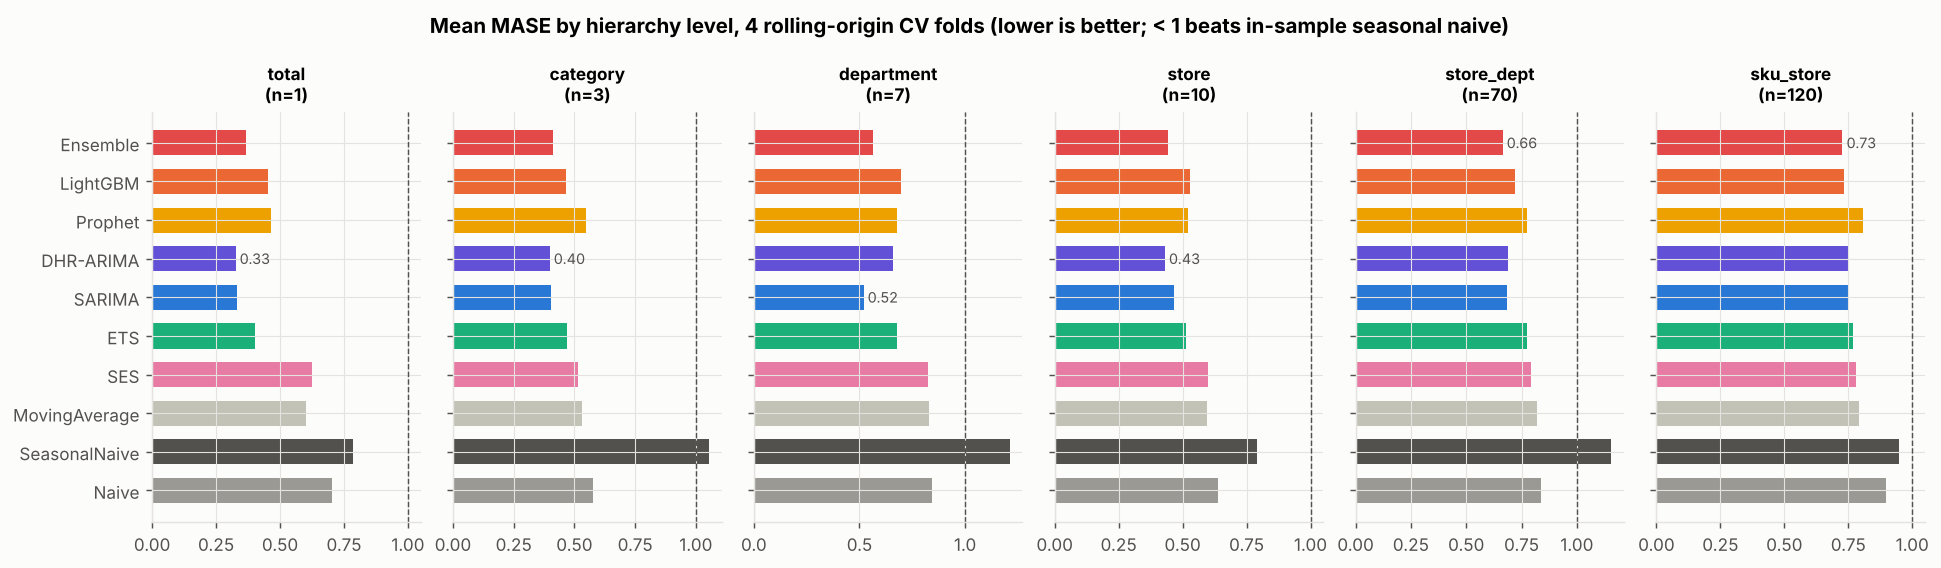

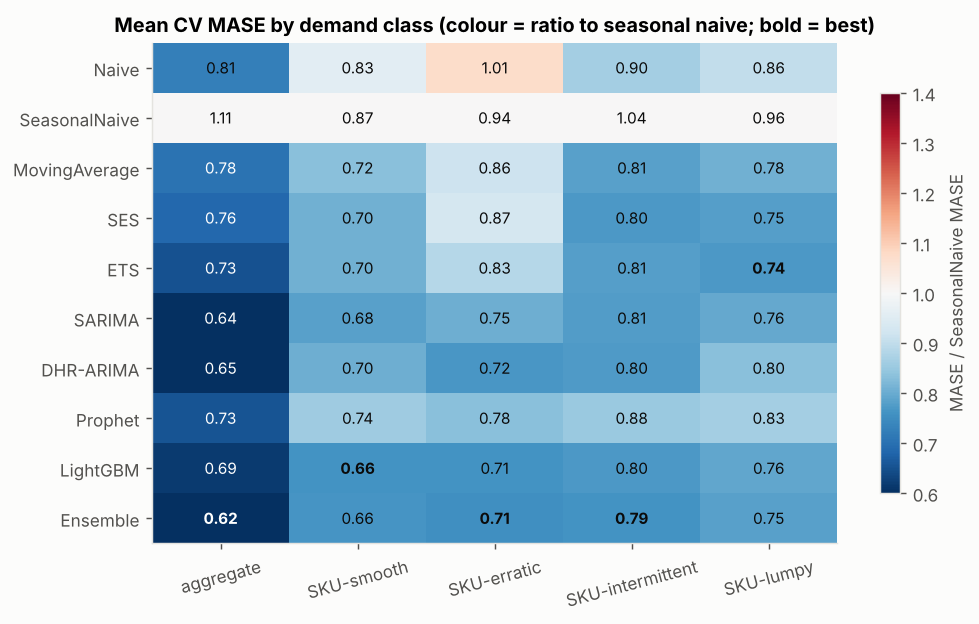

In [5]:
show("07_leaderboard_by_level.png")
show("08_mase_by_class_heatmap.png")

- **Department level** is where SARIMA is most clearly ahead (0.519 vs 0.566 Ensemble, 0.660 DHR).
- **Total / category / store:** DHR-ARIMA and SARIMA are essentially tied (total 0.326 vs 0.331).
- **SKU classes:** LightGBM or the Ensemble win smooth, erratic and intermittent SKUs; **ETS is best on lumpy SKUs** (0.739); all models are within about 0.07 MASE of each other on intermittent SKUs. There is little signal to find there.

## 4. Fold-by-fold stability

In [6]:
display(pd.read_csv("reports/tables/fold_by_fold_mean_MASE.csv").set_index("model").round(3))

,cv1,cv2,cv3,cv4,holdout
model,,,,,
Naive,0.841,0.838,0.863,0.896,0.826
SeasonalNaive,1.029,1.002,1.017,1.031,1.051
MovingAverage,0.720,0.781,0.808,0.846,0.752
SES,0.700,0.795,0.789,0.803,0.748
ETS,0.729,0.769,0.739,0.764,0.739
SARIMA,0.690,0.734,0.694,0.687,0.699
DHR-ARIMA,0.698,0.726,0.693,0.714,0.728
Prophet,0.758,0.807,0.781,0.749,0.789
LightGBM,0.669,0.728,0.712,0.741,0.678


The top group (Ensemble, SARIMA, DHR-ARIMA, LightGBM) stays in the top group in every fold; LightGBM is the best *single* model in cv1 (0.669) but the worst of the four in cv4 (0.741), which illustrates why a single split would be fragile.

## 5. Are the differences real? Diebold-Mariano and paired bootstrap

In [7]:
display(pd.read_csv("reports/tables/bootstrap_mase_diff.csv").round(4))
display(pd.read_csv("reports/tables/dm_tests_summary.csv"))

,model_a,model_b,group,mean_diff,ci95_lo,ci95_hi,n_series,share_a_better,wilcoxon_p
0,Ensemble,DHR-ARIMA,all,-0.0263,-0.0410,-0.0110,211,0.5877,0.0013
1,Ensemble,DHR-ARIMA,Aggregates,-0.0251,-0.0493,-0.0029,91,0.5934,0.0687
2,Ensemble,DHR-ARIMA,SKU,-0.0272,-0.0481,-0.0060,120,0.5833,0.0083
3,Ensemble,SARIMA,all,-0.0198,-0.0295,-0.0107,211,0.6777,0.0000
4,Ensemble,SARIMA,Aggregates,-0.0151,-0.0296,-0.0010,91,0.6154,0.0149
5,Ensemble,SARIMA,SKU,-0.0233,-0.0362,-0.0107,120,0.7250,0.0000
6,LightGBM,SeasonalNaive,all,-0.3077,-0.3627,-0.2599,211,0.8436,0.0000
7,LightGBM,SeasonalNaive,Aggregates,-0.4272,-0.5315,-0.3384,91,0.8462,0.0000
8,LightGBM,SeasonalNaive,SKU,-0.2170,-0.2588,-0.1775,120,0.8417,0.0000
9,SARIMA,DHR-ARIMA,all,-0.0065,-0.0228,0.0102,211,0.5024,0.5787


,model_a,model_b,group,A significantly better,B significantly better,no significant difference
0,Ensemble,DHR-ARIMA,Aggregate,12,3,76
1,Ensemble,DHR-ARIMA,SKU,20,5,95
2,Ensemble,SARIMA,Aggregate,13,5,73
3,Ensemble,SARIMA,SKU,17,6,97
4,LightGBM,SeasonalNaive,Aggregate,40,0,51
5,LightGBM,SeasonalNaive,SKU,53,2,65
6,SARIMA,DHR-ARIMA,Aggregate,9,2,80
7,SARIMA,DHR-ARIMA,SKU,13,9,98
8,SARIMA,ETS,Aggregate,19,1,71
9,SARIMA,ETS,SKU,7,7,106


**Bootstrap across series (mean MASE difference A − B, 95% CI):**
- SARIMA vs LightGBM, aggregates: **−0.050 [−0.084, −0.017]**, so SARIMA is significantly better.
- SARIMA vs LightGBM, SKUs: **+0.018 [−0.004, +0.040]** (Wilcoxon p = 0.036). LightGBM is better, but the CI includes 0: weak evidence.
- SARIMA vs DHR-ARIMA: −0.007 [−0.023, +0.010], a **tie**.
- SARIMA vs ETS, aggregates: −0.089 [−0.121, −0.060], so SARIMA is clearly better; on SKUs the two tie.
- Ensemble vs SARIMA, all series: −0.020 [−0.030, −0.011]. A small but consistent gain (Ensemble better on 68% of series).

**Per-series DM tests** (65 forecast weeks per series): for SARIMA vs LightGBM, **75 of 91 aggregates and 99 of 120 SKUs show no significant difference**. Individual series are too short to separate good models; the differences only become visible when pooled across many series. Versus seasonal naive, SARIMA is significantly better on 43 aggregates and 41 SKUs, and significantly worse on 4 series in total.

## 6. Prediction-interval calibration

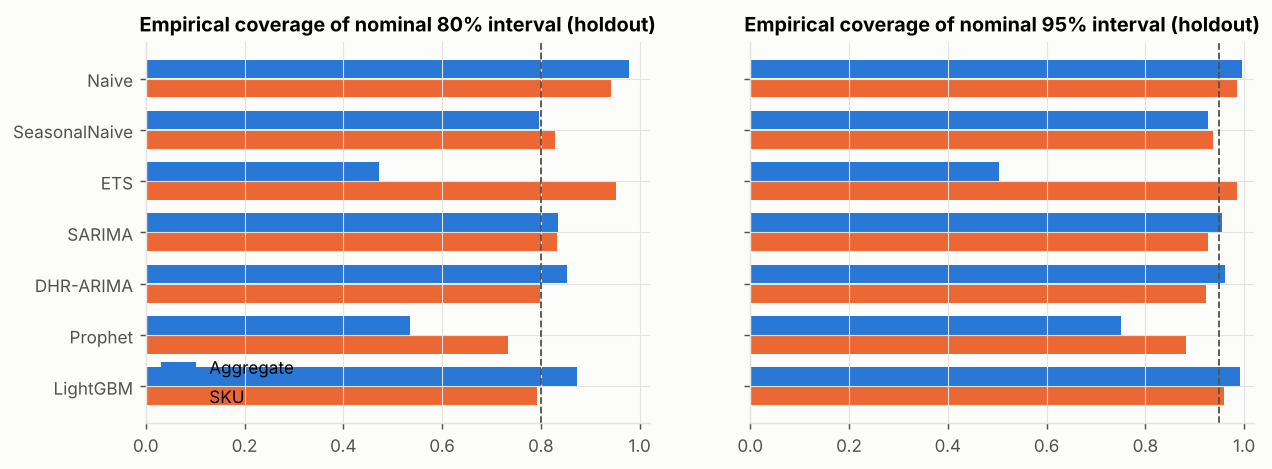

,model,group,cov80,cov95,n_windows,period
0,DHR-ARIMA,Aggregate,0.846,0.955,364,cv
1,DHR-ARIMA,SKU,0.828,0.940,480,cv
2,ETS,Aggregate,0.498,0.537,364,cv
3,ETS,SKU,0.963,0.989,480,cv
4,LightGBM,Aggregate,0.803,0.951,364,cv
5,LightGBM,SKU,0.799,0.948,480,cv
6,Naive,Aggregate,0.948,0.982,364,cv
7,Naive,SKU,0.962,0.989,480,cv
8,Prophet,Aggregate,0.584,0.775,364,cv
9,Prophet,SKU,0.739,0.886,480,cv


In [8]:
show("10_interval_coverage.png")
display(pd.read_csv("reports/tables/interval_coverage.csv").round(3))

**Observed:** SARIMA (CV: 83% / 94% aggregates, 86% / 95% SKUs), DHR-ARIMA and LightGBM's empirical intervals are close to nominal 80% / 95%. **ETS intervals are far too narrow on aggregates (50% / 54% coverage)** and **Prophet's are too narrow too (58% / 78%)**. ETS on SKUs over-covers (96%).
**Why it matters:** an 80% interval that covers 50% would set safety stocks far too low. Calibration has to be *checked*, not assumed. (Likely causes: ETS with heuristic seasonal initialisation understates state uncertainty on trending aggregates; Prophet's intervals ignore seasonal-parameter uncertainty and short-term autocorrelation.)

## 7. What LightGBM relies on, and a robustness check of the price assumption

In [9]:
display(pd.read_csv("reports/tables/lgbm_feature_importance.csv").head(12).round(3))
display(pd.read_csv("reports/tables/lgbm_tuning.csv").round(4).head(6))
display(pd.read_csv("reports/tables/lgbm_ablation_no_price.csv"))

,feature,gain,gain_share
0,slag104,5568863.841,0.267
1,store_c,1794118.945,0.086
2,price_rel52,1338015.776,0.064
3,rmean4,1287746.622,0.062
4,slope26,1227879.092,0.059
5,woy,1222374.601,0.059
6,zero52,1014357.384,0.049
7,age,979680.939,0.047
8,scale_log,793571.017,0.038
9,rstd52,729834.957,0.035


,num_leaves,learning_rate,min_data_in_leaf,feature_fraction,n_estimators,mean_MASE_tuning,MASE_tune1,MASE_tune2
0,31,0.03,50,0.8,600,0.7081,0.7191,0.6970
1,63,0.03,50,0.8,300,0.7107,0.7228,0.6987
2,63,0.03,50,0.8,600,0.7113,0.7140,0.7086
3,15,0.03,200,0.8,600,0.7124,0.7244,0.7003
4,31,0.03,200,0.8,300,0.7158,0.7229,0.7087
5,31,0.03,50,0.8,300,0.7161,0.7300,0.7023


,period,group,no_price,with_price
0,cv,Aggregate,0.6915,0.6855
1,cv,SKU,0.7408,0.7327
2,holdout,Aggregate,0.5718,0.5636
3,holdout,SKU,0.7647,0.7644


- The top features are the 2-year and 1-year seasonal lags, store identity, recent level/trend, week of year and the price ratio. LightGBM learns seasonality *from lags* rather than from a fixed seasonal structure.
- **Tuning** (2 pre-CV origins only): all 12 grid points scored mean MASE between 0.708 and 0.736, so hyper-parameters matter little; the chosen point is 31 leaves, min 50 per leaf, 600 trees, learning rate 0.03.
- **Price ablation:** the price features use the *planned* price of the target week (assumed known). Without them, CV MASE moves from 0.733 to 0.741 (SKU) and from 0.686 to 0.692 (aggregates), so **no conclusion depends on that assumption**.
- **Why trees cannot extrapolate:** a tree predicts averages of training targets in its leaves, so it cannot output a value beyond what it has seen. Scaling every target by the series' recent 52-week mean (and predicting the *ratio*) is what lets one model serve series of very different sizes and moving levels; the remaining weakness is visible on strongly trending aggregates, where LightGBM loses to SARIMA.